In [ ]:
# --- project root (added when the folder was organised): run notebooks from the project folder
import os, sys
from pathlib import Path
_p = Path.cwd()
while not (_p / "preprocess.py").exists() and _p != _p.parent:
    _p = _p.parent
os.chdir(_p); sys.path.insert(0, str(_p))
print("working folder:", _p)

# 05b — Compare all models on the round-3 val and test sets

Uses `data_r3/` (8 validation regions) and writes all outputs to **`runs/comparison_r3/`**, so the earlier `runs/comparison_*` files from notebook 05 are kept. Model weights are only read, never changed.

Finds **every finished run** in `runs/` (04a/b/c, 06 experiments, later runs) and evaluates each
`best.pth` on the **current** validation and test sets. Re-evaluating (instead of reading old
`metrics.json`) matters: the validation set was enlarged from 4 to 8 regions, so all runs must be
scored on the same patches.

Outputs (all in `runs/comparison_r3/`): `comparison_*.csv`, `comparison_*.png`, `test_confusion_<run>.png`.

**Rules for reading it**
* Choose a model by **validation mIoU**. Test numbers are for the report, not for choosing.
* Gaps smaller than ~0.02–0.03 mIoU are likely noise — check the seed spread (Section 2) when you have repeated runs.
* Per-region / per-month mIoU only average the classes that occur in that subset.

In [1]:
import sys, json
sys.path.append(".")
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
import train_lib_r3 as tl
from train_lib_r3 import NC, DEV
from preprocess import CLASSES, IGNORE, COLORS, load_stats

DATA = Path("data_r3")
OUT = Path("runs") / "comparison_r3"; OUT.mkdir(parents=True, exist_ok=True)
stats = load_stats(DATA / "norm_stats.json")
index = pd.read_csv(DATA / "patch_index.csv")
index["file"] = index["file"].str.replace("\\", "/", regex=False)

runs = {}
for d in sorted(Path("runs").iterdir()):
    if not (d / "best.pth").exists() or not (d / "config.json").exists():
        continue
    cfg = json.load(open(d / "config.json"))
    if "RUN_NAME" not in cfg or tl.arch_of(cfg) is None:      # skips the old 03_training runs
        continue
    runs[cfg["RUN_NAME"]] = cfg
print(f"{len(runs)} runs found:", list(runs))
print("val regions:", sorted(index[index.split == 'val'].region.unique()))
print("test regions:", sorted(index[index.split == 'test'].region.unique()))

7 runs found: ['A_unet_resnet34', 'A_unet_v2', 'B_deeplab_v2', 'B_deeplabv3plus_resnet50', 'C_segformer_mitb2', 'C_segformer_v2', 'C_segformer_v3']
val regions: ['bangkok', 'danube_delta', 'iowa', 'las_vegas', 'madrid', 'saskatchewan', 'serengeti', 'sudd_wetland']
test regions: ['black_forest', 'cairo', 'hungary_plain', 'mekong_delta', 'namib_desert', 'okavango']


## 1. Evaluate every run on validation and test

In [2]:
def load_split(split):
    files = index[index.split == split].reset_index(drop=True)
    ds = tl.EvalPatches(files.file, DATA, stats, f"loading {split}")
    return ds, np.repeat(files.region.values, 12), np.array(ds.month)

val_ds, val_region, val_month = load_split("val")
test_ds, test_region, test_month = load_split("test")

@torch.no_grad()
def run_eval(model, ds, region_of, month_of):
    dl = torch.utils.data.DataLoader(ds, 32, shuffle=False)
    cm_all = torch.zeros(NC, NC, dtype=torch.long, device=DEV)
    cm_reg = {r: torch.zeros_like(cm_all) for r in np.unique(region_of)}
    cm_mon = {m: torch.zeros_like(cm_all) for m in range(12)}
    k = 0
    for x, y in dl:
        x, y = x.to(DEV), y.to(DEV)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEV == "cuda")):
            p = model(x).argmax(1)
        for b in range(len(x)):
            c = tl.confusion(p[b], y[b])
            cm_all += c; cm_reg[region_of[k]] += c; cm_mon[month_of[k]] += c; k += 1
    oa, iou, f1 = tl.scores(cm_all)
    return dict(cm=cm_all, oa=oa, miou=float(iou.mean()), iou=iou, f1=f1,
                region={r: tl.miou_present(c) for r, c in cm_reg.items()},
                month={m + 1: tl.miou_present(c) for m, c in cm_mon.items()})

R = {}
for name, cfg in runs.items():
    model = tl.build_model(tl.arch_of(cfg)).to(DEV)
    model.load_state_dict(torch.load(Path("runs") / name / "best.pth", map_location=DEV)); model.eval()
    R[name] = dict(cfg=cfg, val=run_eval(model, val_ds, val_region, val_month),
                   test=run_eval(model, test_ds, test_region, test_month),
                   params=tl.count_params(model))
    h = pd.read_csv(Path("runs") / name / "history.csv")
    R[name]["epochs"], R[name]["minutes"] = len(h), h.seconds.sum() / 60
    print(f"{name:26s} val mIoU {R[name]['val']['miou']:.3f} | test mIoU {R[name]['test']['miou']:.3f}")
    del model
    if DEV == "cuda": torch.cuda.empty_cache()

loading val:   0%|          | 0/128 [00:00<?, ?it/s]

loading test:   0%|          | 0/96 [00:00<?, ?it/s]

A_unet_resnet34            val mIoU 0.430 | test mIoU 0.577
A_unet_v2                  val mIoU 0.488 | test mIoU 0.625
B_deeplab_v2               val mIoU 0.500 | test mIoU 0.610
B_deeplabv3plus_resnet50   val mIoU 0.497 | test mIoU 0.605
C_segformer_mitb2          val mIoU 0.502 | test mIoU 0.534
C_segformer_v2             val mIoU 0.536 | test mIoU 0.616
C_segformer_v3             val mIoU 0.543 | test mIoU 0.618


## 2. Summary tables

In [3]:
summary = pd.DataFrame({n: {"model": r["cfg"].get("MODEL_NAME", n), "group": r["cfg"].get("GROUP", n),
                            "val OA": r["val"]["oa"], "val mIoU": r["val"]["miou"],
                            "test OA": r["test"]["oa"], "test mIoU": r["test"]["miou"],
                            "params (M)": r["params"], "epochs": r["epochs"], "train min": r["minutes"],
                            "loss": r["cfg"].get("LOSS", "dice" if r["cfg"].get("USE_DICE", True) else "none"),
                            "LR": r["cfg"].get("LR")}
                        for n, r in R.items()}).T
for c in ["val OA", "val mIoU", "test OA", "test mIoU", "params (M)", "train min"]:
    summary[c] = summary[c].astype(float).round(3)
summary = summary.sort_values("val mIoU", ascending=False)
summary.to_csv(OUT / "comparison_summary.csv")
display(summary)
print("Best by validation mIoU:", summary.index[0])

groups = summary.groupby("group")[["val mIoU", "test mIoU"]].agg(["mean", "std", "count"]).round(3)
if (groups[("val mIoU", "count")] > 1).any():
    print("\nGroups with repeated seeds (mean ± std):"); display(groups)

,model,group,val OA,val mIoU,test OA,test mIoU,params (M),epochs,train min,loss,LR
C_segformer_v3,SegFormer / MiT-B2 v3,C_segformer_v3,0.764,0.543,0.756,0.618,24.724,48,12.311,lovasz,0.00006
C_segformer_v2,SegFormer / MiT-B2 v2,C_segformer_v2,0.761,0.536,0.754,0.616,24.724,42,8.826,lovasz,0.0001
C_segformer_mitb2,SegFormer / MiT-B2,C_segformer_mitb2,0.723,0.502,0.666,0.534,24.724,15,2.987,dice,0.0001
B_deeplab_v2,DeepLabV3+ / ResNet-50 v2,B_deeplab_v2,0.730,0.500,0.748,0.610,26.679,60,12.424,lovasz,0.0003
B_deeplabv3plus_resnet50,DeepLabV3+ / ResNet-50,B_deeplabv3plus_resnet50,0.738,0.497,0.740,0.605,26.679,31,6.056,dice,0.0003
A_unet_v2,U-Net / ResNet-34 v2,A_unet_v2,0.708,0.488,0.755,0.625,24.437,60,12.146,lovasz,0.0003
A_unet_resnet34,U-Net / ResNet-34,A_unet_resnet34,0.650,0.430,0.717,0.577,24.437,30,5.696,dice,0.0003


Best by validation mIoU: C_segformer_v3


In [4]:
val_iou  = pd.DataFrame({n: r["val"]["iou"]  for n, r in R.items()}, index=CLASSES).T.round(3).loc[summary.index]
test_iou = pd.DataFrame({n: r["test"]["iou"] for n, r in R.items()}, index=CLASSES).T.round(3).loc[summary.index]
test_f1  = pd.DataFrame({n: r["test"]["f1"]  for n, r in R.items()}, index=CLASSES).T.round(3).loc[summary.index]
val_iou.to_csv(OUT / "comparison_val_iou.csv"); test_iou.to_csv(OUT / "comparison_test_iou.csv"); test_f1.to_csv(OUT / "comparison_test_f1.csv")
print("Validation IoU per class"); display(val_iou.style.highlight_max(axis=0, color="#cde8cd"))
print("Test IoU per class");       display(test_iou.style.highlight_max(axis=0, color="#cde8cd"))
print("Test F1 per class");        display(test_f1.style.highlight_max(axis=0, color="#cde8cd"))

Validation IoU per class


,Trees,Grass/Shrub,Cropland,Built-up,Bare,Water,Wetland
C_segformer_v3,0.337000,0.593000,0.419000,0.775000,0.255000,0.694000,0.727000
C_segformer_v2,0.351000,0.589000,0.377000,0.776000,0.247000,0.697000,0.718000
C_segformer_mitb2,0.396000,0.454000,0.381000,0.757000,0.202000,0.684000,0.639000
B_deeplab_v2,0.344000,0.527000,0.300000,0.767000,0.230000,0.689000,0.642000
B_deeplabv3plus_resnet50,0.354000,0.548000,0.277000,0.770000,0.160000,0.656000,0.714000
A_unet_v2,0.347000,0.489000,0.254000,0.749000,0.228000,0.696000,0.653000
A_unet_resnet34,0.335000,0.287000,0.282000,0.752000,0.184000,0.653000,0.521000


Test IoU per class


,Trees,Grass/Shrub,Cropland,Built-up,Bare,Water,Wetland
C_segformer_v3,0.614000,0.252000,0.650000,0.821000,0.882000,0.810000,0.300000
C_segformer_v2,0.637000,0.297000,0.656000,0.824000,0.853000,0.811000,0.234000
C_segformer_mitb2,0.554000,0.211000,0.591000,0.694000,0.650000,0.762000,0.275000
B_deeplab_v2,0.610000,0.271000,0.610000,0.815000,0.844000,0.811000,0.308000
B_deeplabv3plus_resnet50,0.578000,0.296000,0.615000,0.768000,0.916000,0.791000,0.269000
A_unet_v2,0.597000,0.316000,0.613000,0.784000,0.932000,0.827000,0.309000
A_unet_resnet34,0.555000,0.199000,0.594000,0.710000,0.866000,0.739000,0.375000


Test F1 per class


,Trees,Grass/Shrub,Cropland,Built-up,Bare,Water,Wetland
C_segformer_v3,0.761000,0.403000,0.788000,0.902000,0.937000,0.895000,0.462000
C_segformer_v2,0.779000,0.458000,0.793000,0.903000,0.921000,0.895000,0.380000
C_segformer_mitb2,0.713000,0.348000,0.743000,0.819000,0.788000,0.865000,0.431000
B_deeplab_v2,0.758000,0.427000,0.758000,0.898000,0.915000,0.896000,0.471000
B_deeplabv3plus_resnet50,0.733000,0.457000,0.762000,0.869000,0.956000,0.883000,0.424000
A_unet_v2,0.747000,0.480000,0.760000,0.879000,0.965000,0.906000,0.472000
A_unet_resnet34,0.714000,0.332000,0.745000,0.830000,0.928000,0.850000,0.545000


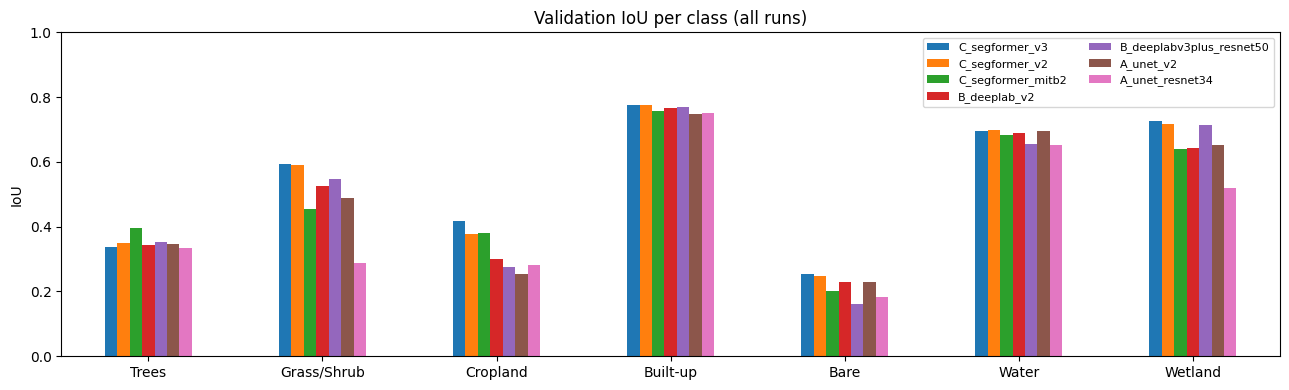

In [5]:
ax = val_iou.T.plot.bar(figsize=(13, 4), rot=0, title="Validation IoU per class (all runs)")
ax.set_ylabel("IoU"); ax.set_ylim(0, 1); ax.legend(fontsize=8, ncol=2); plt.tight_layout()
plt.savefig(OUT / "comparison_val_iou.png", dpi=150); plt.show()

## 3. Training curves

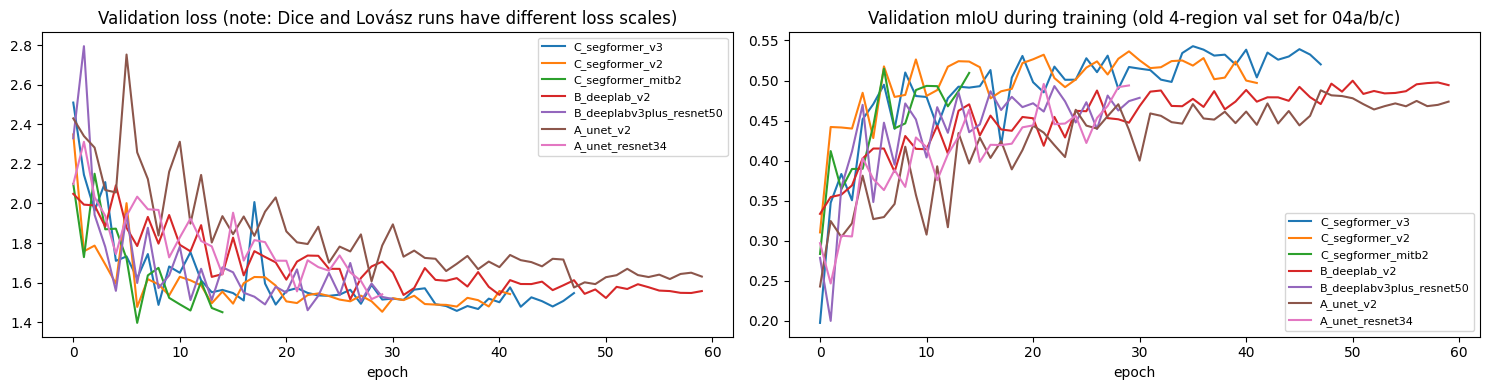

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for name in summary.index:
    h = pd.read_csv(Path("runs") / name / "history.csv")
    ax[0].plot(h.epoch, h.val_loss, label=name); ax[1].plot(h.epoch, h.val_miou, label=name)
ax[0].set_title("Validation loss (note: Dice and Lovász runs have different loss scales)")
ax[1].set_title("Validation mIoU during training (old 4-region val set for 04a/b/c)")
for a in ax: a.set_xlabel("epoch"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "comparison_curves.png", dpi=150); plt.show()

## 4. Per region and per month (test)
* **Per region:** low values = poor generalisation to that kind of landscape.
* **Per month:** dips (often December–February) = **seasonal confusion**, which the prototype would report as fake land-cover change.

Test mIoU per region


,C_segformer_v3,C_segformer_v2,C_segformer_mitb2,B_deeplab_v2,B_deeplabv3plus_resnet50,A_unet_v2,A_unet_resnet34
black_forest,0.268,0.269,0.222,0.245,0.240,0.258,0.222
cairo,0.348,0.346,0.262,0.345,0.319,0.311,0.274
hungary_plain,0.370,0.396,0.301,0.389,0.347,0.391,0.345
mekong_delta,0.349,0.336,0.299,0.335,0.325,0.334,0.328
namib_desert,0.133,0.180,0.097,0.126,0.137,0.139,0.130
okavango,0.150,0.132,0.115,0.139,0.161,0.131,0.080


Validation mIoU per region


,C_segformer_v3,C_segformer_v2,C_segformer_mitb2,B_deeplab_v2,B_deeplabv3plus_resnet50,A_unet_v2,A_unet_resnet34
bangkok,0.242,0.247,0.256,0.241,0.255,0.264,0.247
danube_delta,0.294,0.304,0.287,0.296,0.282,0.279,0.284
iowa,0.357,0.363,0.334,0.335,0.328,0.358,0.345
las_vegas,0.210,0.239,0.178,0.237,0.212,0.222,0.224
madrid,0.259,0.259,0.268,0.317,0.264,0.264,0.260
saskatchewan,0.186,0.169,0.150,0.136,0.113,0.121,0.113
serengeti,0.136,0.139,0.117,0.125,0.155,0.113,0.041
sudd_wetland,0.202,0.205,0.209,0.256,0.234,0.202,0.201


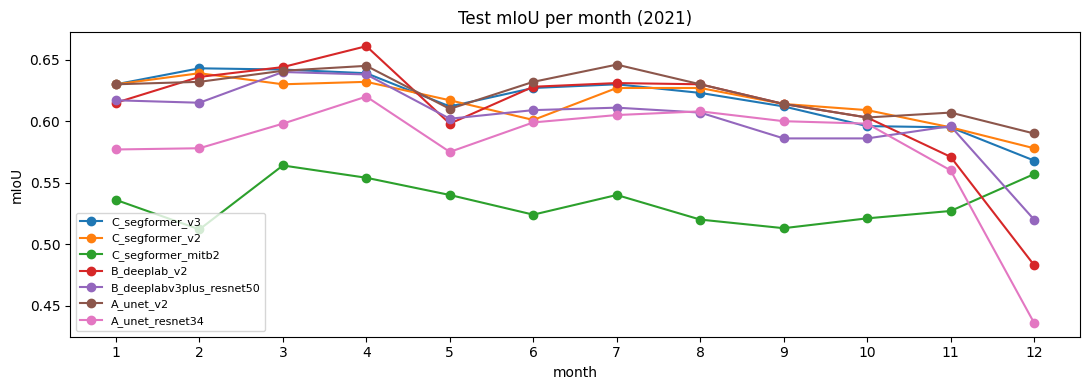

Spread over the year (max - min mIoU), smaller = more seasonally stable:


,spread
C_segformer_mitb2,0.052
A_unet_v2,0.056
C_segformer_v2,0.061
C_segformer_v3,0.075
B_deeplabv3plus_resnet50,0.120
B_deeplab_v2,0.178
A_unet_resnet34,0.184


In [7]:
by_region = pd.DataFrame({n: r["test"]["region"] for n, r in R.items()}).round(3)[summary.index]
by_month  = pd.DataFrame({n: r["test"]["month"]  for n, r in R.items()}).round(3)[summary.index]
val_region_tab = pd.DataFrame({n: r["val"]["region"] for n, r in R.items()}).round(3)[summary.index]
by_region.to_csv(OUT / "comparison_test_by_region.csv"); by_month.to_csv(OUT / "comparison_test_by_month.csv")
val_region_tab.to_csv(OUT / "comparison_val_by_region.csv")
print("Test mIoU per region");       display(by_region)
print("Validation mIoU per region"); display(val_region_tab)

ax = by_month.plot(marker="o", figsize=(11, 4), title="Test mIoU per month (2021)")
ax.set_xlabel("month"); ax.set_ylabel("mIoU"); ax.set_xticks(range(1, 13)); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "comparison_test_by_month.png", dpi=150); plt.show()
print("Spread over the year (max - min mIoU), smaller = more seasonally stable:")
display((by_month.max() - by_month.min()).round(3).sort_values().to_frame("spread"))

## 5. Confusion matrices (test) — top 3 runs by validation mIoU

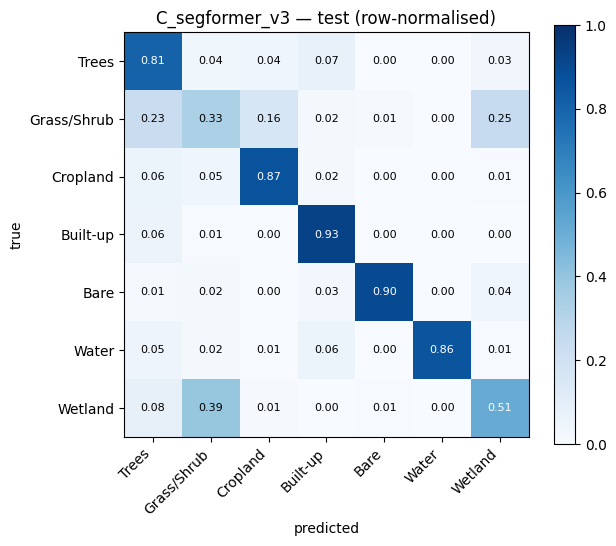

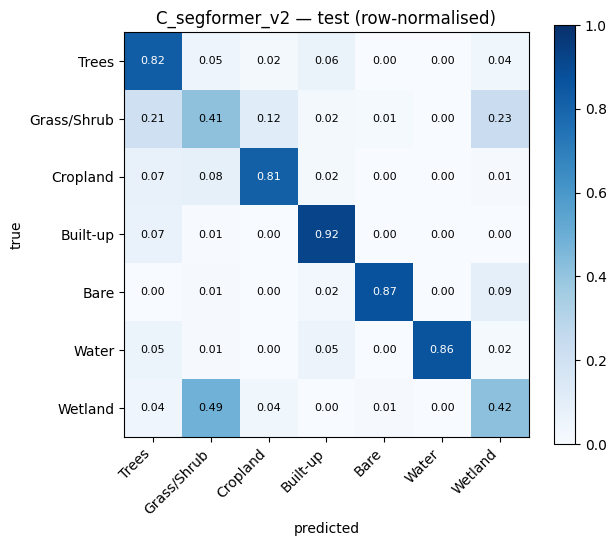

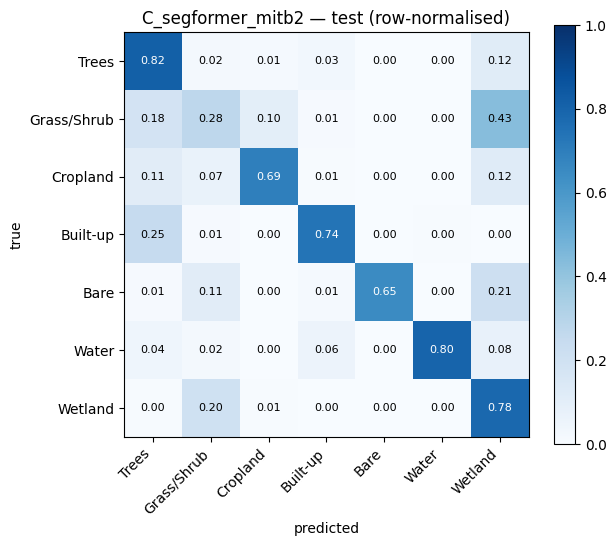

In [8]:
for name in summary.index[:3]:
    tl.plot_confusion(R[name]["test"]["cm"], OUT / f"test_confusion_{name}.png",
                      f"{name} — test (row-normalised)")

## 6. Same test patches, top 4 runs

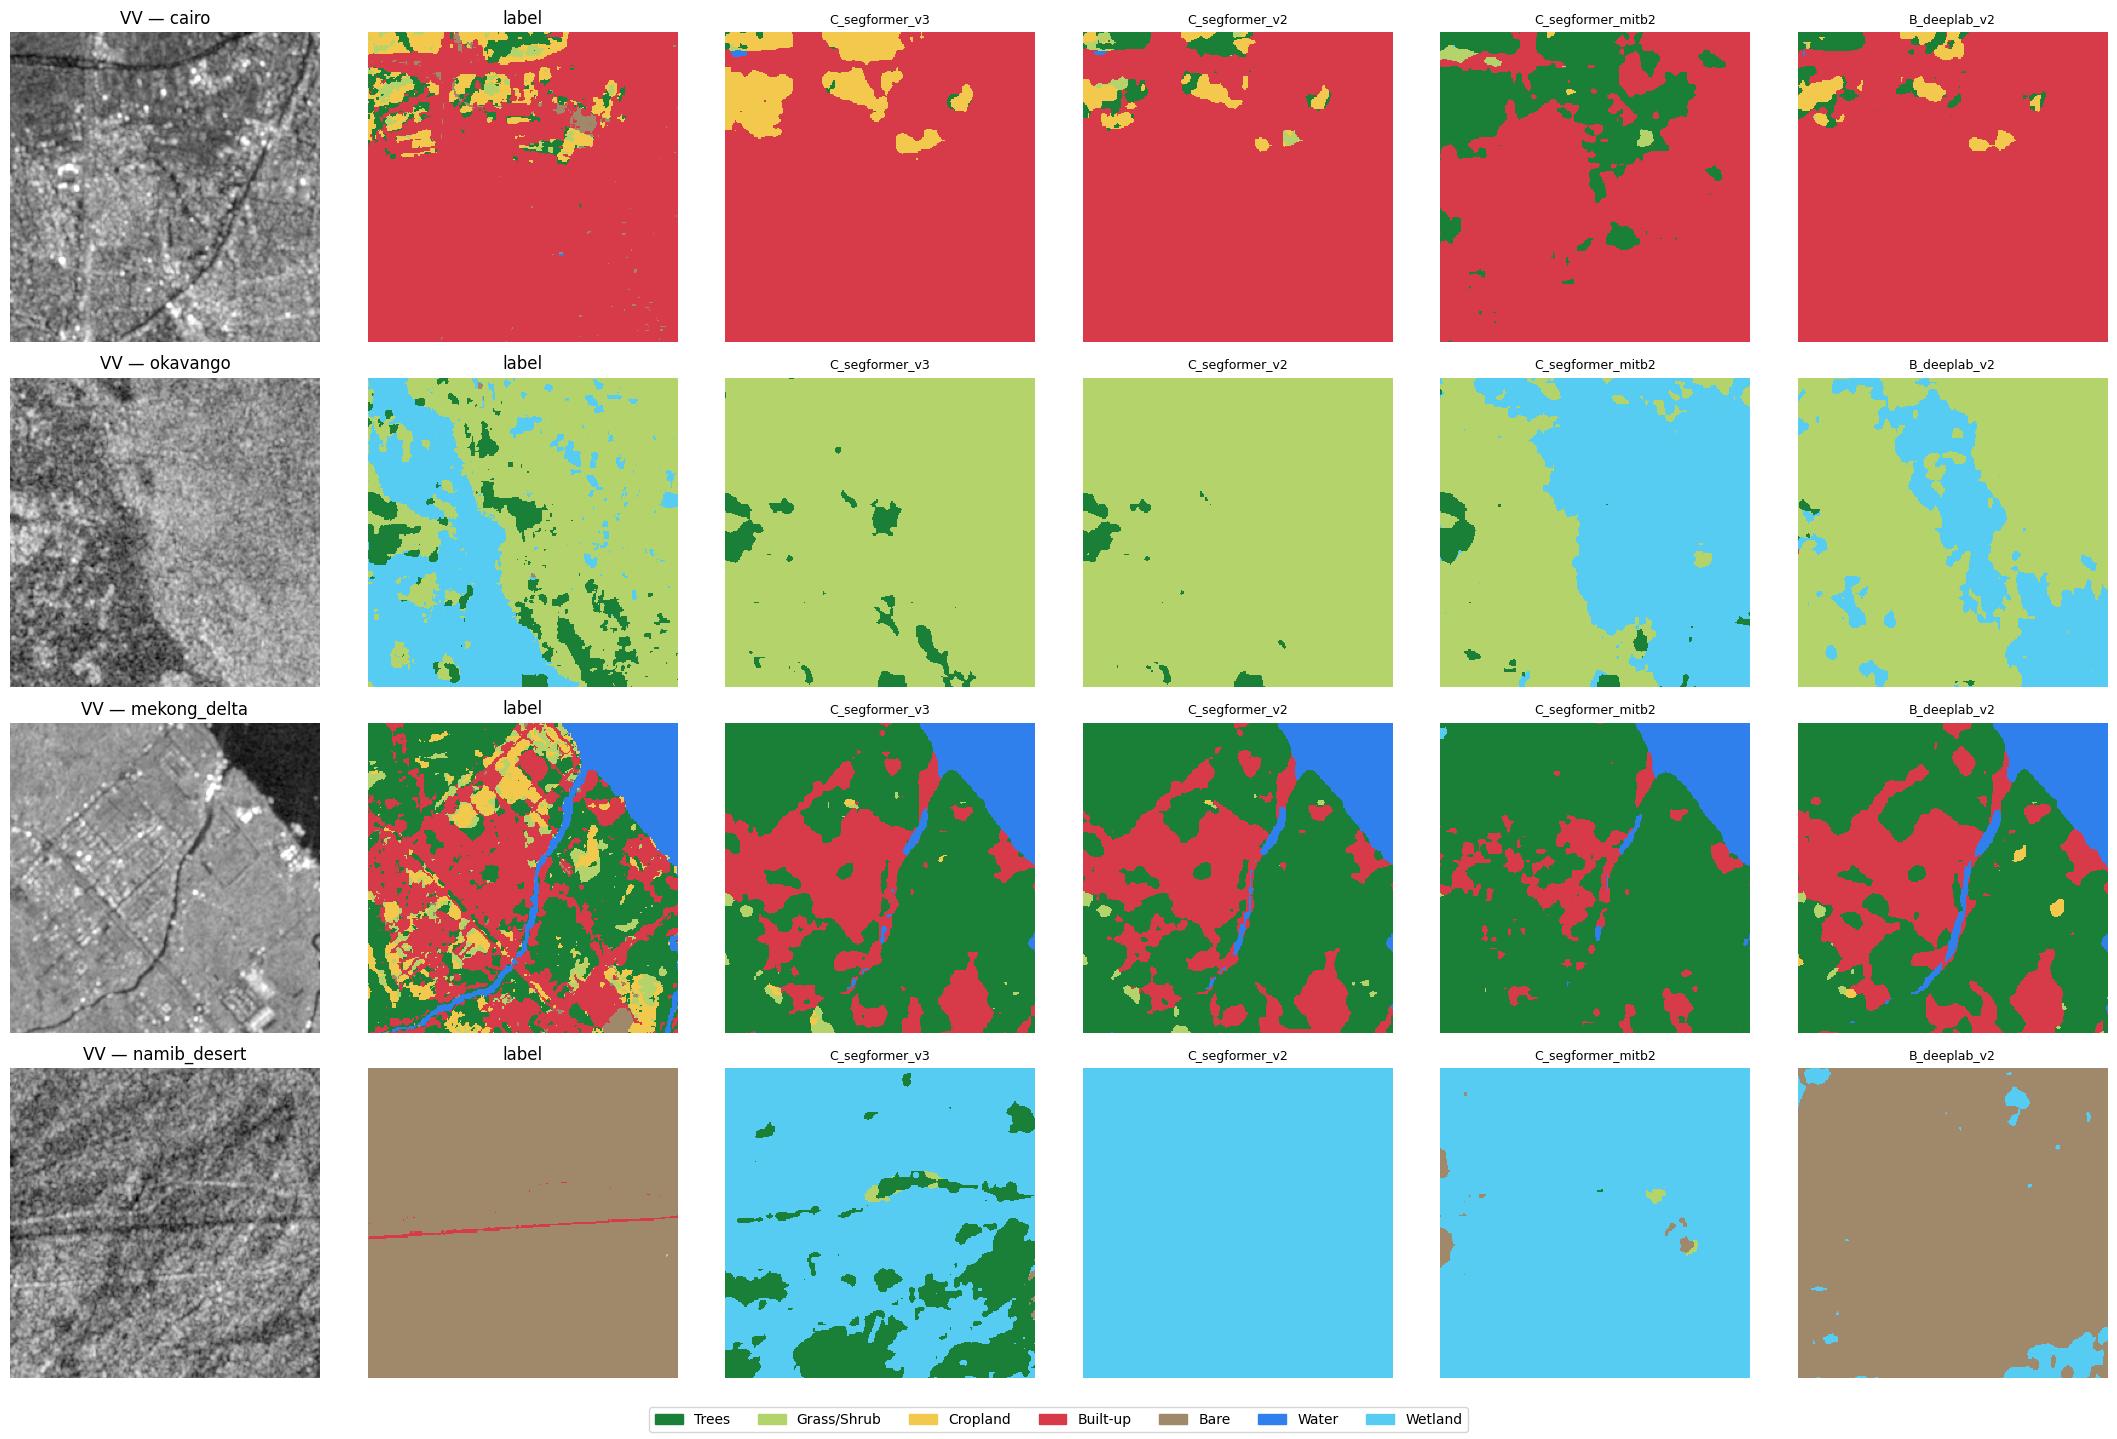

In [9]:
from matplotlib.colors import ListedColormap
cmap = ListedColormap(COLORS)
top = list(summary.index[:4])
models = {}
for n in top:
    m = tl.build_model(tl.arch_of(R[n]["cfg"])).to(DEV)
    m.load_state_dict(torch.load(Path("runs") / n / "best.pth", map_location=DEV)); m.eval(); models[n] = m

picks = [k for k in range(len(test_ds)) if test_month[k] == 6]                       # July
picks = [picks[i] for i in np.linspace(0, len(picks) - 1, 4).astype(int)]
fig, ax = plt.subplots(len(picks), 2 + len(models), figsize=(3.6 * (2 + len(models)), 3.6 * len(picks)), squeeze=False)
for r, k in enumerate(picks):
    x, y = test_ds[k]
    ax[r, 0].imshow(x[0], cmap="gray"); ax[r, 0].set_title(f"VV — {test_region[k]}")
    ax[r, 1].imshow(np.ma.masked_equal(y.numpy(), IGNORE), cmap=cmap, vmin=0, vmax=NC - 1, interpolation="nearest"); ax[r, 1].set_title("label")
    for c, (n, m) in enumerate(models.items()):
        with torch.no_grad():
            p = m(x[None].to(DEV)).argmax(1)[0].cpu().numpy()
        ax[r, 2 + c].imshow(p, cmap=cmap, vmin=0, vmax=NC - 1, interpolation="nearest"); ax[r, 2 + c].set_title(n, fontsize=9)
    for a in ax[r]: a.axis("off")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS], CLASSES, loc="lower center", ncol=NC)
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.savefig(OUT / "comparison_test_examples.png", dpi=110); plt.show()

## 7. What to write down
* Best run by **validation mIoU** → its **test** OA, mIoU, per-class IoU and F1.
* Effect of each change: v1 → v2 (longer + Lovász) per model; SegFormer v2 → v3 (regularisation).
* Which classes improved or got worse, generalisation per region, seasonal spread.
* Cost: parameters and training minutes.